In [6]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from clean_mission1 import OUT_DIR
from label_mission1 import HORIZONS, MAIN_CLASSES, folds, load_labels
from evaluate_mission1 import FAR_TARGETS, evaluate, pool

labels = load_labels()
events = pd.read_csv(f'{OUT_DIR}/events.csv', index_col='ID', parse_dates=['onset', 'end'])
os.makedirs('results', exist_ok=True)

In [7]:
# No-skill baseline: random scores, so alarms are independent of the telemetry. Thresholds come from each
# fold's calibration year, exactly as they will for real models. Several seeds smooth out luck.
per_event, summary = [], []
for seed in range(5):
    scores = np.random.default_rng(seed).random(len(labels), dtype=np.float32)
    for f in folds():
        e, s = evaluate(scores, labels, events, f)
        per_event.append(e.assign(seed=seed))
        summary.append(s.assign(seed=seed))
per_event = (pd.concat(per_event).groupby(['ID', 'fold', 'horizon', 'far_target'])  # average over seeds
             .agg(Class=('Class', 'first'), caught=('caught', 'mean'), lead_min=('lead_min', 'mean')).reset_index())
summary = pd.concat(summary)

result = pool(per_event, summary)
result.to_csv('results/random_baseline.csv')
result.round(3)

events  recall  median_lead_min  recall_lo  recall_hi  \
horizon far_target                                                          
5       0.1             57   0.000              NaN      0.000      0.000   
        0.5             57   0.004            3.164      0.000      0.011   
        1.0             57   0.007            3.530      0.000      0.018   
        2.0             57   0.014            3.410      0.004      0.028   
15      0.1             57   0.000              NaN      0.000      0.000   
        0.5             57   0.004            3.164      0.000      0.011   
        1.0             57   0.007            3.530      0.000      0.018   
        2.0             57   0.018            3.656      0.004      0.032   
30      0.1             57   0.000              NaN      0.000      0.000   
        0.5             57   0.007           13.015      0.000      0.018   
        1.0             57   0.011            3.896      0.000      0.025   
        2.0             57   0.025            3.896      0.011      0.042   

                    test_far_per_day  precision  
horizon far_target                               
5       0.1                    0.098        0.0  
        0.5                    0.492        0.0  
        1.0                    0.987        0.0  
        2.0                    1.988        0.0  
15      0.1                    0.098        0.0  
        0.5                    0.492        0.0  
        1.0                    0.987        0.0  
        2.0                    1.988        0.0  
30      0.1                    0.098        0.0  
        0.5                    0.492        0.0  
        1.0                    0.987        0.0  
        2.0                    1.988        0.0

In [8]:
# Sanity check of the scoring: random alarms in r of the 48 half-hour blocks per day
# catch an h-minute window with chance 1 - (1 - r/48)^(h/30)
check = result[['recall', 'test_far_per_day']].copy()
h, r = check.index.get_level_values('horizon'), check.test_far_per_day
check['expected_recall'] = 1 - (1 - r / 48) ** (h / 30)
check.round(4)

recall  test_far_per_day  expected_recall
horizon far_target                                           
5       0.1         0.0000            0.0982           0.0003
        0.5         0.0035            0.4919           0.0017
        1.0         0.0070            0.9871           0.0035
        2.0         0.0140            1.9881           0.0070
15      0.1         0.0000            0.0982           0.0010
        0.5         0.0035            0.4919           0.0051
        1.0         0.0070            0.9871           0.0103
        2.0         0.0175            1.9880           0.0209
30      0.1         0.0000            0.0982           0.0020
        0.5         0.0070            0.4918           0.0102
        1.0         0.0105            0.9872           0.0206
        2.0         0.0246            1.9880           0.0414

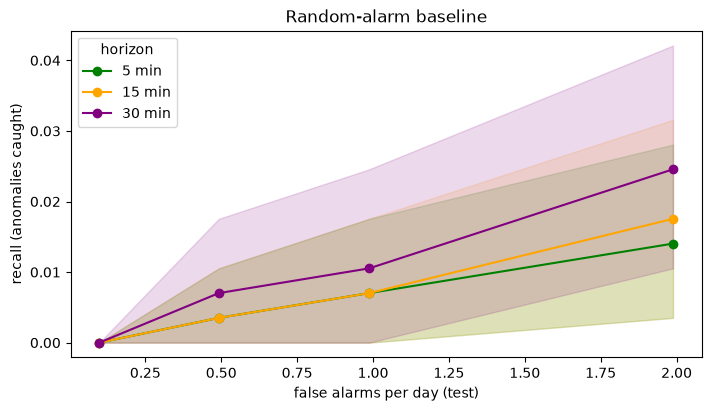

In [9]:
# Recall vs false alarms per day. Real models must sit clearly above these lines.
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
for h, c in zip(HORIZONS, ['green', 'orange', 'purple']):
    r = result.loc[h]
    ax.plot(r.test_far_per_day, r.recall, 'o-', color=c, label=f'{h} min')
    ax.fill_between(r.test_far_per_day, r.recall_lo, r.recall_hi, color=c, alpha=0.15)
ax.set(xlabel='false alarms per day (test)', ylabel='recall (anomalies caught)', title='Random-alarm baseline')
ax.legend(title='horizon')
plt.show()

In [10]:
# Per class, for the two classes with enough test events
by_class = pool(per_event[per_event.Class.isin(MAIN_CLASSES)], summary, by=['Class'])
by_class[['events', 'recall', 'recall_lo', 'recall_hi']].round(3)

events  recall  recall_lo  recall_hi
horizon far_target Class                                        
5       0.1        class_3      24   0.000        0.0      0.000
                   class_7      23   0.000        0.0      0.000
        0.5        class_3      24   0.000        0.0      0.000
                   class_7      23   0.000        0.0      0.000
        1.0        class_3      24   0.008        0.0      0.025
                   class_7      23   0.000        0.0      0.000
        2.0        class_3      24   0.017        0.0      0.042
                   class_7      23   0.009        0.0      0.026
15      0.1        class_3      24   0.000        0.0      0.000
                   class_7      23   0.000        0.0      0.000
        0.5        class_3      24   0.000        0.0      0.000
                   class_7      23   0.000        0.0      0.000
        1.0        class_3      24   0.008        0.0      0.025
                   class_7      23   0.000        0.0      0.000
        2.0        class_3      24   0.025        0.0      0.058
                   class_7      23   0.009        0.0      0.026
30      0.1        class_3      24   0.000        0.0      0.000
                   class_7      23   0.000        0.0      0.000
        0.5        class_3      24   0.000        0.0      0.000
                   class_7      23   0.000        0.0      0.000
        1.0        class_3      24   0.008        0.0      0.025
                   class_7      23   0.000        0.0      0.000
        2.0        class_3      24   0.025        0.0      0.058
                   class_7      23   0.017        0.0      0.043